# 🔧 EcoSense — Predictive Maintenance Analysis
## Sensor Health Scoring & Maintenance Scheduling

This notebook covers:

1. **Sensor Health Score Computation** — 0–100 composite score per sensor
2. **Degradation Trend Analysis** — Identifying sensors trending toward failure
3. **Maintenance Window Recommendation** — When to schedule maintenance
4. **Cost-Benefit Analysis** — Preventive vs reactive maintenance
5. **Additional Data Collection Proposal** — What extra data would improve predictions

In [15]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats as sp_stats

from src.feature_engineering import engineer_features, compute_sensor_health_score
from src.data_generator import SENSOR_CONFIG

plt.style.use('seaborn-v0_8-darkgrid')
print('Predictive maintenance modules loaded!')

Predictive maintenance modules loaded!


In [16]:
# Load data
water_df = pd.read_csv('../data/raw/water_quality.csv', parse_dates=['timestamp'])
air_df = pd.read_csv('../data/raw/air_quality.csv', parse_dates=['timestamp'])
anomaly_log = pd.read_csv('../data/anomalies/injected_anomalies.csv', parse_dates=['start_time', 'end_time'])

water_sensors = ['pH', 'turbidity_ntu', 'dissolved_oxygen_mg_l', 'temperature_c', 'conductivity_us_cm']
air_sensors = ['co2_ppm', 'nox_ppm', 'so2_ppm', 'pm25_ug_m3']

# Normal ranges
water_ranges = {s: (c['normal_min'], c['normal_max']) for s, c in SENSOR_CONFIG['water_quality'].items()}
air_ranges = {s: (c['normal_min'], c['normal_max']) for s, c in SENSOR_CONFIG['air_quality'].items()}

print(f'Data loaded. Water: {water_df.shape}, Air: {air_df.shape}')

Data loaded. Water: (17281, 13), Air: (17281, 11)


---
## 1. Feature Engineering & Health Scores

In [17]:
# Engineer features for water quality
water_featured = engineer_features(
    water_df, 
    sensor_columns=water_sensors,
    normal_ranges=water_ranges,
    timestamp_col='timestamp'
)

print(f'\nWater features shape: {water_featured.shape}')

  Engineering features for 5 sensors...
    ✓ Temporal features added
    ✓ Rolling features added
    ✓ Rate of change features added
    ✓ Deviation features added
    ✓ Cumulative stress features added
    ✓ Health scores computed
  ✅ Total new features: 140

Water features shape: (17281, 153)


In [18]:
# Engineer features for air quality
air_featured = engineer_features(
    air_df,
    sensor_columns=air_sensors,
    normal_ranges=air_ranges,
    timestamp_col='timestamp'
)

print(f'\nAir features shape: {air_featured.shape}')

  Engineering features for 4 sensors...
    ✓ Temporal features added
    ✓ Rolling features added
    ✓ Rate of change features added
    ✓ Deviation features added
    ✓ Cumulative stress features added
    ✓ Health scores computed
  ✅ Total new features: 114

Air features shape: (17281, 125)


In [19]:
# Visualize health scores over time
health_cols_water = [f'{s}_health_score' for s in water_sensors]
health_cols_air = [f'{s}_health_score' for s in air_sensors]

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=['Water Quality — Sensor Health Scores', 'Air Quality — Sensor Health Scores'],
    vertical_spacing=0.12
)

# Resample to daily for cleaner visualization
water_daily = water_featured.set_index('timestamp')[health_cols_water].resample('1D').mean()
air_daily = air_featured.set_index('timestamp')[health_cols_air].resample('1D').mean()

colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B1F2B']
for idx, col in enumerate(health_cols_water):
    sensor_name = col.replace('_health_score', '')
    fig.add_trace(
        go.Scatter(x=water_daily.index, y=water_daily[col],
                  name=sensor_name, line=dict(width=2, color=colors[idx])),
        row=1, col=1
    )

colors_air = ['#E63946', '#457B9D', '#1D3557', '#F4A261']
for idx, col in enumerate(health_cols_air):
    sensor_name = col.replace('_health_score', '')
    fig.add_trace(
        go.Scatter(x=air_daily.index, y=air_daily[col],
                  name=sensor_name, line=dict(width=2, color=colors_air[idx])),
        row=2, col=1
    )

# Add threshold lines
for row in [1, 2]:
    fig.add_hline(y=70, line_dash='dash', line_color='orange', opacity=0.5, 
                  annotation_text='Warning (70)', row=row, col=1)
    fig.add_hline(y=50, line_dash='dash', line_color='red', opacity=0.5,
                  annotation_text='Critical (50)', row=row, col=1)

fig.update_yaxes(range=[0, 100], title_text='Health Score')
fig.update_layout(height=700, template='plotly_white',
                  title_text='Sensor Health Monitoring Dashboard')
fig.show()

---
## 2. Degradation Trend Analysis

In [20]:
# Calculate weekly health score trends
water_weekly = water_featured.set_index('timestamp')[health_cols_water].resample('1W').mean()

print('=== Weekly Health Score Trends (Water Quality) ===')
print('Positive slope = improving, Negative slope = degrading\n')

trend_results = []

for col in health_cols_water:
    sensor_name = col.replace('_health_score', '')
    values = water_weekly[col].dropna().values
    x = np.arange(len(values))
    
    slope, intercept, r_value, p_value, std_err = sp_stats.linregress(x, values)
    
    status = '🟢 Stable' if abs(slope) < 0.5 else ('🔴 Degrading' if slope < -0.5 else '🟡 Improving')
    
    print(f'  {sensor_name:30s} | Slope: {slope:+.3f}/week | R²: {r_value**2:.3f} | {status}')
    
    trend_results.append({
        'sensor': sensor_name,
        'weekly_slope': round(slope, 3),
        'r_squared': round(r_value**2, 3),
        'current_health': round(values[-1], 1),
        'status': status,
        'category': 'Water Quality'
    })

print('\n=== Weekly Health Score Trends (Air Quality) ===')
air_weekly = air_featured.set_index('timestamp')[health_cols_air].resample('1W').mean()

for col in health_cols_air:
    sensor_name = col.replace('_health_score', '')
    values = air_weekly[col].dropna().values
    x = np.arange(len(values))
    
    slope, intercept, r_value, p_value, std_err = sp_stats.linregress(x, values)
    status = '🟢 Stable' if abs(slope) < 0.5 else ('🔴 Degrading' if slope < -0.5 else '🟡 Improving')
    
    print(f'  {sensor_name:30s} | Slope: {slope:+.3f}/week | R²: {r_value**2:.3f} | {status}')
    
    trend_results.append({
        'sensor': sensor_name,
        'weekly_slope': round(slope, 3),
        'r_squared': round(r_value**2, 3),
        'current_health': round(values[-1], 1),
        'status': status,
        'category': 'Air Quality'
    })

trend_df = pd.DataFrame(trend_results)
trend_df

=== Weekly Health Score Trends (Water Quality) ===
Positive slope = improving, Negative slope = degrading

  pH                             | Slope: +0.301/week | R²: 0.384 | 🟢 Stable
  turbidity_ntu                  | Slope: +0.028/week | R²: 0.029 | 🟢 Stable
  dissolved_oxygen_mg_l          | Slope: -0.046/week | R²: 0.036 | 🟢 Stable
  temperature_c                  | Slope: +0.237/week | R²: 0.103 | 🟢 Stable
  conductivity_us_cm             | Slope: +0.178/week | R²: 0.606 | 🟢 Stable

=== Weekly Health Score Trends (Air Quality) ===
  co2_ppm                        | Slope: +0.141/week | R²: 0.309 | 🟢 Stable
  nox_ppm                        | Slope: -0.014/week | R²: 0.005 | 🟢 Stable
  so2_ppm                        | Slope: +0.176/week | R²: 0.625 | 🟢 Stable
  pm25_ug_m3                     | Slope: -0.203/week | R²: 0.348 | 🟢 Stable


,sensor,weekly_slope,r_squared,current_health,status,category
0,pH,0.301,0.384,94.7,🟢 Stable,Water Quality
1,turbidity_ntu,0.028,0.029,94.0,🟢 Stable,Water Quality
2,dissolved_oxygen_mg_l,-0.046,0.036,88.7,🟢 Stable,Water Quality
3,temperature_c,0.237,0.103,87.0,🟢 Stable,Water Quality
4,conductivity_us_cm,0.178,0.606,97.9,🟢 Stable,Water Quality
5,co2_ppm,0.141,0.309,90.0,🟢 Stable,Air Quality
6,nox_ppm,-0.014,0.005,94.0,🟢 Stable,Air Quality
7,so2_ppm,0.176,0.625,92.2,🟢 Stable,Air Quality
8,pm25_ug_m3,-0.203,0.348,84.7,🟢 Stable,Air Quality


---
## 3. Maintenance Window Recommendation

In [21]:
# Estimate when each sensor might reach critical health
print('=== Maintenance Schedule Recommendations ===')
print()

maintenance_schedule = []

# Standardized health tiers:
# 85–100 = Optimal
# 70–84  = Normal
# 50–69  = Warning
# <50    = Critical

CRITICAL_THRESHOLD = 50
WARNING_THRESHOLD = 70
NORMAL_THRESHOLD = 70
OPTIMAL_THRESHOLD = 85

for _, row in trend_df.iterrows():
    current = row['current_health']
    slope = row['weekly_slope']
    sensor = row['sensor']

    # Determine health tier
    if current >= OPTIMAL_THRESHOLD:
        tier = 'Optimal'
    elif current >= NORMAL_THRESHOLD:
        tier = 'Normal'
    elif current >= WARNING_THRESHOLD:
        tier = 'Warning'
    else:
        tier = 'Critical'

    # Degrading sensor
    if slope < -0.1 and current > CRITICAL_THRESHOLD:
        weeks_to_critical = (current - CRITICAL_THRESHOLD) / abs(slope)
        weeks_to_warning = max(
            0,
            (current - WARNING_THRESHOLD) / abs(slope)
        )

        urgency = (
            'HIGH' if weeks_to_critical < 4
            else 'MEDIUM' if weeks_to_critical < 12
            else 'LOW'
        )

        print(f'  🔧 {sensor}')
        print(f'     Current Health: {current:.0f}/100 ({tier})')
        print(f'     Degradation Rate: {slope:.3f}/week')
        print(f'     Weeks to Warning ({WARNING_THRESHOLD}): ~{weeks_to_warning:.0f} weeks')
        print(f'     Weeks to Critical (<{CRITICAL_THRESHOLD}): ~{weeks_to_critical:.0f} weeks')
        print(f'     Urgency: {urgency}')
        print()

        maintenance_schedule.append({
            'sensor': sensor,
            'current_health': current,
            'degradation_rate': slope,
            'health_tier': tier,
            'weeks_to_warning': round(weeks_to_warning),
            'weeks_to_critical': round(weeks_to_critical),
            'urgency': urgency,
            'recommended_action':
                'Calibration'
                if weeks_to_critical > 8
                else 'Inspection + Calibration'
        })

    # Already in Warning/Critical territory
    elif current < WARNING_THRESHOLD:
        print(f'  ⚠️ {sensor} — {tier} (Health: {current:.0f}/100)')
        print('     IMMEDIATE maintenance recommended.')
        print()

        maintenance_schedule.append({
            'sensor': sensor,
            'current_health': current,
            'degradation_rate': slope,
            'health_tier': tier,
            'weeks_to_warning': 0,
            'weeks_to_critical': (
                0
                if current < CRITICAL_THRESHOLD
                else round(
                    (current - CRITICAL_THRESHOLD) /
                    max(abs(slope), 0.01)
                )
            ),
            'urgency':
                'CRITICAL'
                if current < CRITICAL_THRESHOLD
                else 'HIGH',
            'recommended_action':
                'Immediate Replacement'
                if current < CRITICAL_THRESHOLD
                else 'Urgent Inspection'
        })

    # Optimal / Normal
    else:
        print(
            f'  ✅ {sensor} — {tier} '
            f'(Health: {current:.0f}/100). '
            'No maintenance needed.'
        )
        print()

if maintenance_schedule:
    schedule_df = pd.DataFrame(maintenance_schedule)
    schedule_df = schedule_df.sort_values('weeks_to_critical')

    schedule_df.to_csv(
        '../data/processed/maintenance_schedule.csv',
        index=False
    )

    print(
        '\nMaintenance schedule saved to '
        'data/processed/maintenance_schedule.csv'
    )

=== Maintenance Schedule Recommendations ===

  ✅ pH — Optimal (Health: 95/100). No maintenance needed.

  ✅ turbidity_ntu — Optimal (Health: 94/100). No maintenance needed.

  ✅ dissolved_oxygen_mg_l — Optimal (Health: 89/100). No maintenance needed.

  ✅ temperature_c — Optimal (Health: 87/100). No maintenance needed.

  ✅ conductivity_us_cm — Optimal (Health: 98/100). No maintenance needed.

  ✅ co2_ppm — Optimal (Health: 90/100). No maintenance needed.

  ✅ nox_ppm — Optimal (Health: 94/100). No maintenance needed.

  ✅ so2_ppm — Optimal (Health: 92/100). No maintenance needed.

  🔧 pm25_ug_m3
     Current Health: 85/100 (Normal)
     Degradation Rate: -0.203/week
     Weeks to Warning (70): ~72 weeks
     Weeks to Critical (<50): ~171 weeks
     Urgency: LOW


Maintenance schedule saved to data/processed/maintenance_schedule.csv


---
## 4. Cost-Benefit Analysis

In [22]:
# Simplified cost model
COSTS = {
    'preventive_calibration': 50000,      # ¥50,000 - scheduled calibration
    'preventive_inspection': 30000,        # ¥30,000 - scheduled inspection
    'reactive_repair': 200000,             # ¥200,000 - unplanned repair
    'reactive_replacement': 500000,        # ¥500,000 - emergency replacement
    'downtime_per_hour': 100000,           # ¥100,000 - production loss per hour
    'regulatory_fine': 1000000,            # ¥1,000,000 - environmental violation fine
}

# Estimate costs for different strategies
n_sensors = len(water_sensors) + len(air_sensors)
n_anomaly_events = len(anomaly_log)

# Strategy 1: No monitoring (reactive only)
reactive_cost = (
    n_anomaly_events * 0.3 * COSTS['reactive_repair'] +  # 30% need repair
    n_anomaly_events * 0.05 * COSTS['reactive_replacement'] +  # 5% need replacement
    n_anomaly_events * 0.1 * COSTS['downtime_per_hour'] * 4 +  # 10% cause 4h downtime
    n_anomaly_events * 0.02 * COSTS['regulatory_fine']  # 2% cause regulatory issues
)

# Strategy 2: Scheduled maintenance (every 3 months)
scheduled_cost = (
    n_sensors * 2 * COSTS['preventive_calibration'] +  # 2 calibrations per sensor
    n_sensors * 4 * COSTS['preventive_inspection'] +   # 4 inspections per sensor
    n_anomaly_events * 0.1 * COSTS['reactive_repair']  # Still 10% reactive repairs
)

# Strategy 3: Predictive maintenance (our system)
predictive_cost = (
    n_sensors * 1 * COSTS['preventive_calibration'] +  # Targeted calibrations
    n_sensors * 2 * COSTS['preventive_inspection'] +   # Targeted inspections
    n_anomaly_events * 0.03 * COSTS['reactive_repair'] # Only 3% reactive (early detection)
)

print('=== Cost-Benefit Analysis (6-month period) ===')
print(f'  Number of sensors: {n_sensors}')
print(f'  Anomaly events: {n_anomaly_events}')
print()
print(f'  Strategy 1 — Reactive Only:        ¥{reactive_cost:>12,.0f}')
print(f'  Strategy 2 — Scheduled:            ¥{scheduled_cost:>12,.0f}')
print(f'  Strategy 3 — Predictive (EcoSense): ¥{predictive_cost:>12,.0f}')
print()
savings_vs_reactive = reactive_cost - predictive_cost
savings_vs_scheduled = scheduled_cost - predictive_cost
print(f'  💰 Savings vs Reactive: ¥{savings_vs_reactive:,.0f} ({savings_vs_reactive/reactive_cost*100:.0f}%)')
print(f'  💰 Savings vs Scheduled: ¥{savings_vs_scheduled:,.0f} ({savings_vs_scheduled/scheduled_cost*100:.0f}%)')

=== Cost-Benefit Analysis (6-month period) ===
  Number of sensors: 9
  Anomaly events: 69

  Strategy 1 — Reactive Only:        ¥  10,005,000
  Strategy 2 — Scheduled:            ¥   3,360,000
  Strategy 3 — Predictive (EcoSense): ¥   1,404,000

  💰 Savings vs Reactive: ¥8,601,000 (86%)
  💰 Savings vs Scheduled: ¥1,956,000 (58%)


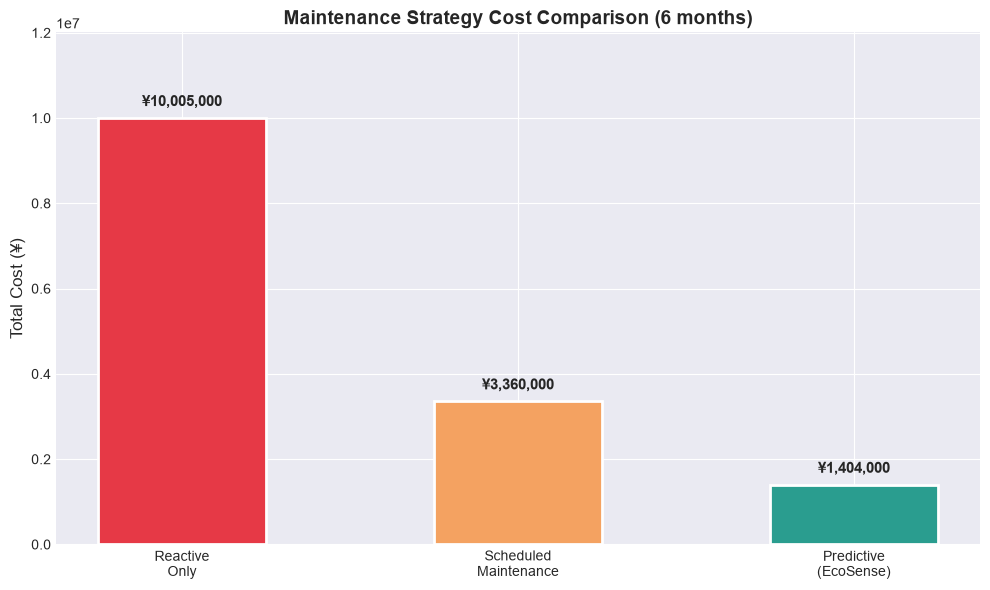

In [23]:
# Visualize cost comparison
strategies = ['Reactive\nOnly', 'Scheduled\nMaintenance', 'Predictive\n(EcoSense)']
costs = [reactive_cost, scheduled_cost, predictive_cost]
colors = ['#E63946', '#F4A261', '#2A9D8F']

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(strategies, costs, color=colors, edgecolor='white', linewidth=2, width=0.5)

# Add value labels
for bar, cost in zip(bars, costs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(costs)*0.02,
            f'¥{cost:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=11)

ax.set_title('Maintenance Strategy Cost Comparison (6 months)', fontsize=14, fontweight='bold')
ax.set_ylabel('Total Cost (¥)', fontsize=12)
ax.set_ylim(0, max(costs) * 1.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('../reports/cost_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 5. Additional Data Collection Proposal

Based on our analysis, here are recommendations for additional data items
that would improve anomaly detection and predictive maintenance accuracy.

In [24]:
additional_data_proposal = pd.DataFrame([
    {
        'Data Item': 'Equipment Vibration (accelerometer)',
        'Type': 'Time Series',
        'Priority': 'HIGH',
        'Justification': 'Mechanical degradation often precedes sensor drift. '
                        'Vibration data can predict bearing failure and pump issues.',
        'Estimated Improvement': '15-25% better failure prediction'
    },
    {
        'Data Item': 'Ambient Humidity (%)',
        'Type': 'Time Series',
        'Priority': 'MEDIUM',
        'Justification': 'Humidity affects sensor accuracy, especially for gas analyzers. '
                        'Would reduce false positives in anomaly detection.',
        'Estimated Improvement': '10-15% fewer false alarms'
    },
    {
        'Data Item': 'Sensor Calibration History',
        'Type': 'Event Log',
        'Priority': 'HIGH',
        'Justification': 'Knowing when sensors were last calibrated helps distinguish '
                        'drift anomalies from real environmental changes.',
        'Estimated Improvement': '20-30% better drift detection'
    },
    {
        'Data Item': 'Flow Rate (water systems)',
        'Type': 'Time Series',
        'Priority': 'MEDIUM',
        'Justification': 'Flow rate changes affect water quality readings. '
                        'Correlated analysis would improve root cause identification.',
        'Estimated Improvement': '10-20% better root cause analysis'
    },
    {
        'Data Item': 'Production Schedule / Batch Info',
        'Type': 'Event Log',
        'Priority': 'MEDIUM',
        'Justification': 'Different products/processes affect emissions differently. '
                        'This context reduces false positives during batch changes.',
        'Estimated Improvement': '15-20% fewer false alarms'
    },
    {
        'Data Item': 'Weather Data (temperature, wind, rain)',
        'Type': 'External API',
        'Priority': 'LOW',
        'Justification': 'Weather affects atmospheric dispersion and ambient baseline levels. '
                        'Useful for air quality sensor normalization.',
        'Estimated Improvement': '5-10% better baseline modeling'
    },
    {
        'Data Item': 'Sensor Power Supply Voltage',
        'Type': 'Time Series',
        'Priority': 'HIGH',
        'Justification': 'Voltage fluctuations can cause measurement errors. '
                        'Early detection of power issues prevents cascading failures.',
        'Estimated Improvement': '10-15% better failure prediction'
    }
])

print('=== Additional Data Collection Proposal ===')
print()
for _, row in additional_data_proposal.iterrows():
    print(f"📌 {row['Data Item']} [{row['Priority']}]")
    print(f"   Type: {row['Type']}")
    print(f"   Why: {row['Justification']}")
    print(f"   Impact: {row['Estimated Improvement']}")
    print()

additional_data_proposal.to_csv('../data/processed/additional_data_proposal.csv', index=False)
print('Proposal saved to data/processed/additional_data_proposal.csv')

=== Additional Data Collection Proposal ===

📌 Equipment Vibration (accelerometer) [HIGH]
   Type: Time Series
   Why: Mechanical degradation often precedes sensor drift. Vibration data can predict bearing failure and pump issues.
   Impact: 15-25% better failure prediction

📌 Ambient Humidity (%) [MEDIUM]
   Type: Time Series
   Why: Humidity affects sensor accuracy, especially for gas analyzers. Would reduce false positives in anomaly detection.
   Impact: 10-15% fewer false alarms

📌 Sensor Calibration History [HIGH]
   Type: Event Log
   Why: Knowing when sensors were last calibrated helps distinguish drift anomalies from real environmental changes.
   Impact: 20-30% better drift detection

📌 Flow Rate (water systems) [MEDIUM]
   Type: Time Series
   Why: Flow rate changes affect water quality readings. Correlated analysis would improve root cause identification.
   Impact: 10-20% better root cause analysis

📌 Production Schedule / Batch Info [MEDIUM]
   Type: Event Log
   Why: Dif

In [25]:
# Save featured data for dashboard
water_featured.to_csv('../data/processed/water_quality_featured.csv', index=False)
air_featured.to_csv('../data/processed/air_quality_featured.csv', index=False)
trend_df.to_csv('../data/processed/sensor_trends.csv', index=False)

print('✅ Featured data saved for dashboard!')
print(f'   Water: {water_featured.shape}')
print(f'   Air: {air_featured.shape}')
print(f'\n✅ Predictive maintenance analysis complete!')
print('   Next: Launch the Streamlit dashboard with `streamlit run dashboard/app.py`')

✅ Featured data saved for dashboard!
   Water: (17281, 153)
   Air: (17281, 125)

✅ Predictive maintenance analysis complete!
   Next: Launch the Streamlit dashboard with `streamlit run dashboard/app.py`
